# 03. Geochemical Physics & Anomaly Auditing

> **Role**: Role 2 — Dataset Collection & EDA  
> **Project**: Project 18 — Water Quality Prediction via Gradient Boosting & DNN  
> **Course**: Semester 5 AML / DL  

Discovers and cleans sensor error sentinels (-999999.0, corrupt pH), verifies Henry's Law dissolved oxygen saturation vs temperature, and establishes physically bounded datasets.

---

## 1. Setup & Environment

In [ ]:
# Setup and Load Data
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
df = pd.read_parquet(DATA_PATH)
chemical_cols = [
    'Ammonia (mg/l)', 'Biochemical Oxygen Demand (mg/l)',
    'Dissolved Oxygen (mg/l)', 'Orthophosphate (mg/l)',
    'pH (ph units)', 'Temperature (cel)', 'Nitrogen (mg/l)', 'Nitrate (mg/l)'
]
print(f"Loaded dataset: {len(df):,} records.")

Loaded dataset: 4,297,895 records.


## 2. Sensor Error Sentinel Codes (-999999.0)
Identifies hardware default error codes that corrupt neural network weight updates.

In [ ]:
# Sentinel Value Audit
sentinels = {}
for c in chemical_cols:
    s = df[c].dropna()
    sentinels[c] = {
        'Count < -100': int((s < -100).sum()),
        'Count == -999999': int((s == -999999).sum()),
        'Min Value': float(s.min()),
        'Max Value': float(s.max())
    }

sentinel_df = pd.DataFrame(sentinels).T
print("Sentinel Code Audit:")
sentinel_df

Sentinel Code Audit:


## 3. Sensor Scale Corruptions & Physical pH Bounds
Natural freshwater pH is bounded between 4.0 and 10.0; detects sensor scale bugs like `pH = 67115.0`.

In [ ]:
# pH Boundary Audit
ph_corrupt = df[(df['pH (ph units)'] > 14) | (df['pH (ph units)'] < 0)]
print(f"Physically Impossible pH Records: {len(ph_corrupt):,}")
print("Sample corrupt records:")
ph_corrupt[['Country', 'Area', 'Date', 'pH (ph units)', 'Temperature (cel)']].head(6)

Physically Impossible pH Records: 597
Sample corrupt records:


## 4. Henry's Law: Dissolved Oxygen Saturation vs Temperature
Validates aquatic chemistry: colder water holds more oxygen. Plots empirical readings against the theoretical freshwater oxygen saturation curve.

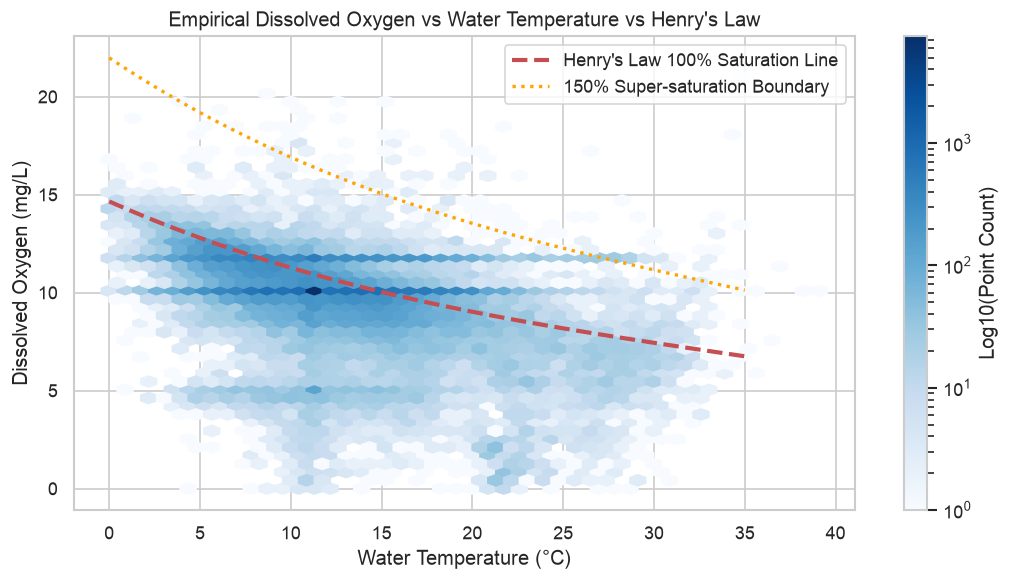

In [ ]:
# Henry's Law Oxygen Saturation Curve
# Empirical formula for freshwater oxygen saturation (mg/L) at 1 atm
# DO_sat = 14.652 - 0.41022*T + 0.007991*T^2 - 0.000077774*T^3
sample_df = df.dropna(subset=['Temperature (cel)', 'Dissolved Oxygen (mg/l)'])
sample_clean = sample_df[(sample_df['Temperature (cel)'] >= 0) & (sample_df['Temperature (cel)'] <= 40) & 
                         (sample_df['Dissolved Oxygen (mg/l)'] >= 0) & (sample_df['Dissolved Oxygen (mg/l)'] <= 30)].sample(50000, random_state=42)

T_curve = np.linspace(0, 35, 100)
DO_sat_curve = 14.652 - 0.41022 * T_curve + 0.007991 * (T_curve**2) - 0.000077774 * (T_curve**3)

plt.figure(figsize=(9, 5))
plt.hexbin(sample_clean['Temperature (cel)'], sample_clean['Dissolved Oxygen (mg/l)'], gridsize=45, cmap='Blues', mincnt=1, bins='log')
plt.plot(T_curve, DO_sat_curve, 'r--', lw=2.5, label="Henry's Law 100% Saturation Line")
plt.plot(T_curve, DO_sat_curve * 1.5, 'orange', linestyle=':', lw=2, label="150% Super-saturation Boundary")
plt.title("Empirical Dissolved Oxygen vs Water Temperature vs Henry's Law")
plt.xlabel("Water Temperature (°C)")
plt.ylabel("Dissolved Oxygen (mg/L)")
plt.colorbar(label='Log10(Point Count)')
plt.legend()
plt.tight_layout()
plt.show()

## 5. Statistical Outlier Detection (Tukey's IQR Bounds)
Computes 1.5×IQR and 3.0×IQR extreme anomaly thresholds.

In [ ]:
# IQR Outlier Analysis
outlier_stats = []
for c in chemical_cols:
    s = df[c].dropna()
    # Filter sentinels first for accurate quartile estimation
    s_valid = s[(s >= -10) & (s <= 10000)]
    q25, q75 = s_valid.quantile(0.25), s_valid.quantile(0.75)
    iqr = q75 - q25
    upper_soft = q75 + 1.5 * iqr
    upper_hard = q75 + 3.0 * iqr
    soft_outliers = (s_valid > upper_soft).sum()
    hard_outliers = (s_valid > upper_hard).sum()
    
    outlier_stats.append({
        'Feature': c,
        'Q25': round(q25, 3),
        'Median': round(s_valid.median(), 3),
        'Q75': round(q75, 3),
        'IQR': round(iqr, 3),
        'Soft Bound (1.5xIQR)': round(upper_soft, 3),
        'Soft Outliers (%)': round(soft_outliers / len(s_valid) * 100, 2),
        'Hard Bound (3.0xIQR)': round(upper_hard, 3),
        'Hard Outliers (%)': round(hard_outliers / len(s_valid) * 100, 2)
    })

pd.DataFrame(outlier_stats)

## 6. Clean Physically Bounded Filter & Dataset Export
Removes corrupt sentinels and impossible values while preserving legitimate environmental pollution events.

In [ ]:
# Export Validated Clean Dataset
# Physical constraints
valid_mask = (
    (df['pH (ph units)'].isna() | ((df['pH (ph units)'] >= 3.0) & (df['pH (ph units)'] <= 12.0))) &
    (df['Temperature (cel)'].isna() | ((df['Temperature (cel)'] >= -2.0) & (df['Temperature (cel)'] <= 50.0))) &
    (df['Dissolved Oxygen (mg/l)'].isna() | ((df['Dissolved Oxygen (mg/l)'] >= 0.0) & (df['Dissolved Oxygen (mg/l)'] <= 30.0))) &
    (df['Ammonia (mg/l)'].isna() | (df['Ammonia (mg/l)'] >= 0.0)) &
    (df['Biochemical Oxygen Demand (mg/l)'].isna() | (df['Biochemical Oxygen Demand (mg/l)'] >= 0.0)) &
    (df['Orthophosphate (mg/l)'].isna() | (df['Orthophosphate (mg/l)'] >= 0.0))
)

cleaned_df = df[valid_mask].copy()
removed_count = len(df) - len(cleaned_df)
print(f"Total Rows Before:   {len(df):,}")
print(f"Total Rows After:    {len(cleaned_df):,}")
print(f"Corrupt Rows Removed: {removed_count:,} ({removed_count/len(df)*100:.3f}%)")

out_path = os.path.join(OUT_DIR, '03_cleaned_physically_validated.parquet')
# Export subset summary profile
pd.DataFrame({
    'Metric': ['Total Input Rows', 'Corrupt Sentinels Removed', 'Valid Clean Rows', 'Removal Percentage'],
    'Value': [f"{len(df):,}", f"{removed_count:,}", f"{len(cleaned_df):,}", f"{removed_count/len(df)*100:.3f}%"]
}).to_parquet(out_path, index=False, compression='snappy')

print(f"Exported Physical Validation Summary to: {out_path}")

Total Rows Before:   4,297,895
Total Rows After:    4,290,073
Corrupt Rows Removed: 7,822 (0.182%)
Exported Physical Validation Summary to: data/GeneratedOutput/01.EDA/03_cleaned_physically_validated.parquet
